In [1]:
# Cell 1: Set paths and processing parameters.
from pathlib import Path
import sys

# Run from implement/ or its parent project directory.
IMPLEMENT_DIR = Path.cwd().resolve()
if not (IMPLEMENT_DIR / "crystal_pipeline.py").is_file():
    IMPLEMENT_DIR = IMPLEMENT_DIR / "implement"
if not (IMPLEMENT_DIR / "crystal_pipeline.py").is_file():
    raise FileNotFoundError("Start Jupyter from implement/ or its parent directory.")
sys.path.insert(0, str(IMPLEMENT_DIR))
PROJECT_ROOT = IMPLEMENT_DIR.parent
INPUT_DIR = IMPLEMENT_DIR / "data"
RUN_DIR = IMPLEMENT_DIR / "outputs" / "all_plates_step1_001"  # Use a new name for different settings.
MODEL_DIR = PROJECT_ROOT / "training/output/step1_only_001/export/implement_bundle/models"
COLOR_REFERENCE_PATH = MODEL_DIR / "rf_step1.pkl"
CONFIG = {
    "data_dir": "data/mag500",
    "target_plates": {
        "old": ["pl01", "pl02", "pl04", "pl07", "pl08", "pl09", "pl11", "pl13", "pl14", "pl15", "pl17", "pl18", "pl19", "pl21", "pl22", "pl23", "pl24", "pl27"],
        "new": ["pl01", "pl02", "pl04", "pl05", "pl06", "pl07", "pl08", "pl09", "pl10", "pl11", "pl12", "pl13", "pl14", "pl15", "pl16", "pl17", "pl18", "pl19"],
    },
    "images_per_plate": None,  # All available images in every selected plate.
    "crop": {"top": 60, "bottom": 100, "left": 60, "right": 100},
    "n_segments": 300, "compactness": 10.0,
}
print(f"Project: {PROJECT_ROOT}\nRun: {RUN_DIR}")

Project: /home/kmanabe2403/dune
Run: /home/kmanabe2403/dune/implement/outputs/all_plates_step1_001


In [2]:
# Cell 2: Save selected image paths and settings (no image loading).
# Re-running Cells 2-4 overwrites outputs. Use a new run name for a separate experiment.
from crystal_pipeline import prepare_run

prepare_run(PROJECT_ROOT, RUN_DIR, CONFIG)

Selected images: 299 | Metadata: /home/kmanabe2403/dune/implement/outputs/all_plates_step1_001/metadata


In [3]:
# Cell 3: Crop images, compute SLIC segments, and save per-image Lab means.
from crystal_preprocessing import run_preprocessing

run_preprocessing(PROJECT_ROOT, RUN_DIR)

Prepared inputs are stored locally in this run; no previous output folder is required.


In [4]:
# Cell 4: Save pixel-Lab corrections using the RF model's own reference.
from crystal_preprocessing import run_color_correction

run_color_correction(RUN_DIR, COLOR_REFERENCE_PATH)

Prepared inputs are stored locally in this run; no previous output folder is required.


In [5]:
# Cell 5: Calculate and save the original 18 RF features, one image at a time.
from crystal_features import run_feature_extraction

run_feature_extraction(RUN_DIR)

Prepared inputs are stored locally in this run; no previous output folder is required.


In [6]:
# Cell 6: Group superpixels by standardized features using PCA and GMM.
# Cluster IDs are local to each image; they are not crystal class labels.
from crystal_gmm import run_gmm

run_gmm(RUN_DIR, n_components=3, pca_components=15, probability_cut=0.90, report_every_plates=20)

Saved results retained; only the progress display has changed.
GMM complete: 20/36 plates (160/299 images)
GMM complete: 36/36 plates (299/299 images)
Output: /home/kmanabe2403/dune/implement/outputs/all_plates_step1_001/gmm


In [7]:
# Cell 7: Classify GMM clusters and save crystal class area ratios.
from crystal_rf import run_rf_classification

model_dir = MODEL_DIR
stage2_paths = {}  # Five-class step1 only.
stage3_paths = {}
run_rf_classification(RUN_DIR, model_dir / "rf_step1.pkl", stage2_paths, stage3_paths, report_every_plates=20)

Saved results retained; only the progress display has changed.
RF complete: 20/36 plates (160/299 images)
RF complete: 36/36 plates (299/299 images)
Output: /home/kmanabe2403/dune/implement/outputs/all_plates_step1_001/rf


## Optional manual corrections

☐ Run Cell 8 to create `review/cluster_corrections.csv`.  
☐ Inspect the example in Cell 9; change group/plate to inspect more images if needed.  
☐ Enter `new_class` only for corrections you want to make.  
・Blank `new_class` keeps RF. No `reviewed` flag is required to continue.

In [8]:
# Cell 8: Create manual review fields; preserve existing run-local entries.
# Corrections are optional: edit new_class only where needed; no reviewed flag required.
from crystal_review import prepare_corrections

CORRECTIONS_PATH = prepare_corrections(RUN_DIR)

Saved 897 clusters: /home/kmanabe2403/dune/implement/outputs/all_plates_step1_001/review/cluster_corrections.csv
Fill new_class only for clusters you want to change; leave other rows blank.
Edits will be applied in a later cell. RF predictions are unchanged.


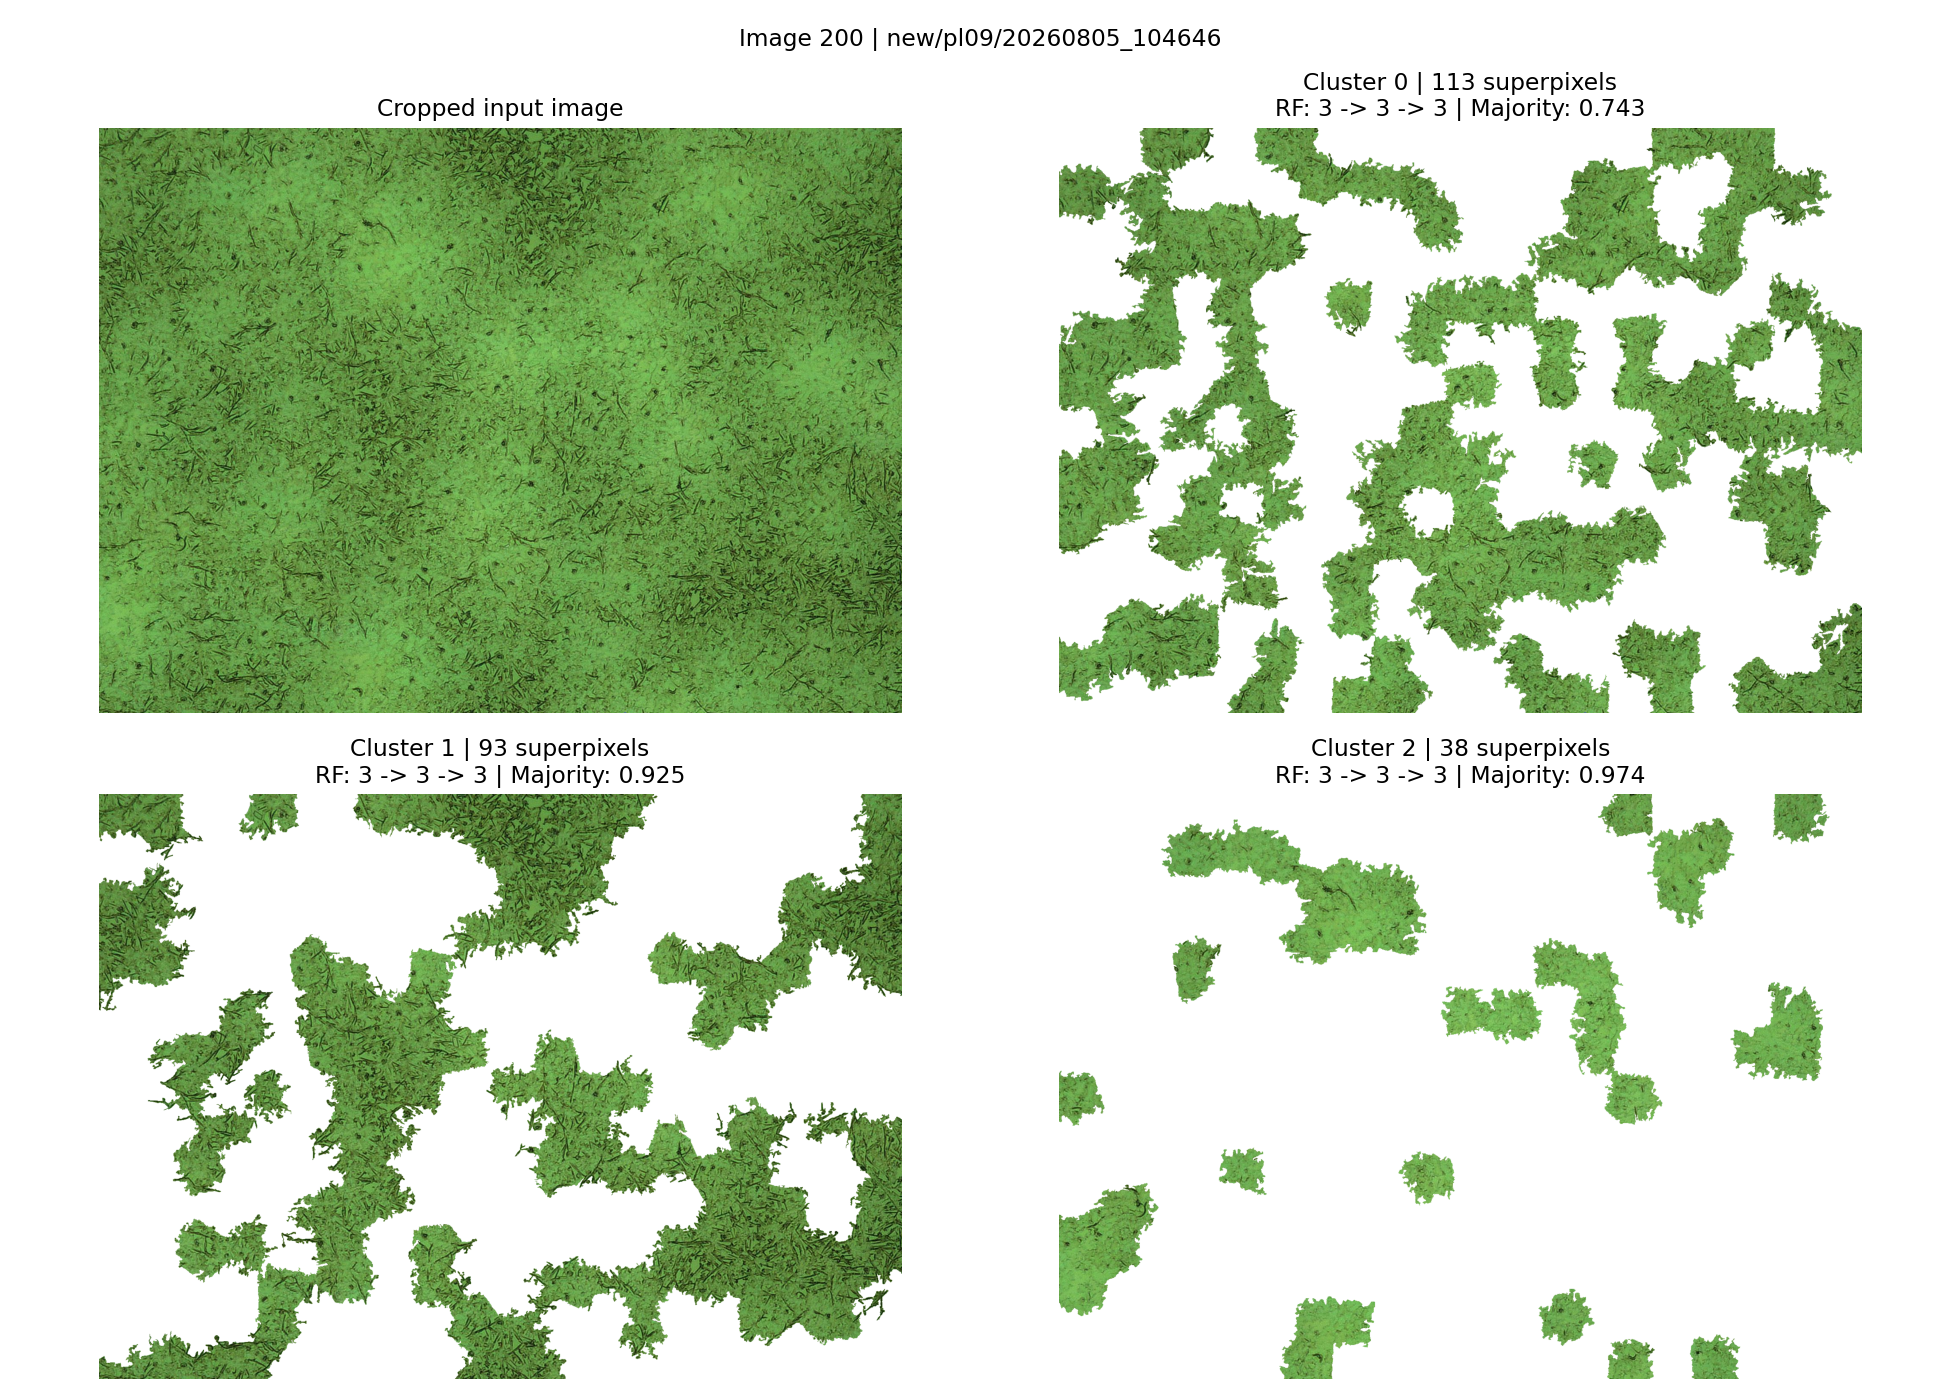

Saved 8 review figures: /home/kmanabe2403/dune/implement/outputs/all_plates_step1_001/review/figures


In [9]:
# Cell 9: Inspect the original image and its GMM clusters for one plate.
# Use image_id and cluster_id to find the matching CSV row.
# Change group/plate as needed; display one image and save all selected review figures.
from crystal_review import show_clusters

show_clusters(RUN_DIR, group="new", plate="pl09")

## Apply optional corrections

☐ Save the CSV if you edited it, then run Cell 10.  
・You can continue without any corrections; blank entries retain RF predictions.  
・Progress in Cells 6, 7 and 10 is reported every 20 completed plates and at completion.

In [10]:
# Cell 10: Apply nonblank new_class entries and recalculate areas.
# Blank new_class keeps RF; reviewed=1 is not required.
# Original RF outputs are preserved; reruns overwrite rf_corrected/.
from crystal_corrections import apply_manual_corrections

apply_manual_corrections(RUN_DIR, report_every_plates=20)

Saved results retained; only the progress display has changed.
Corrections complete: 20/36 plates (160/299 images)
Corrections complete: 36/36 plates (299/299 images)
Output: /home/kmanabe2403/dune/implement/outputs/all_plates_step1_001/rf_corrected


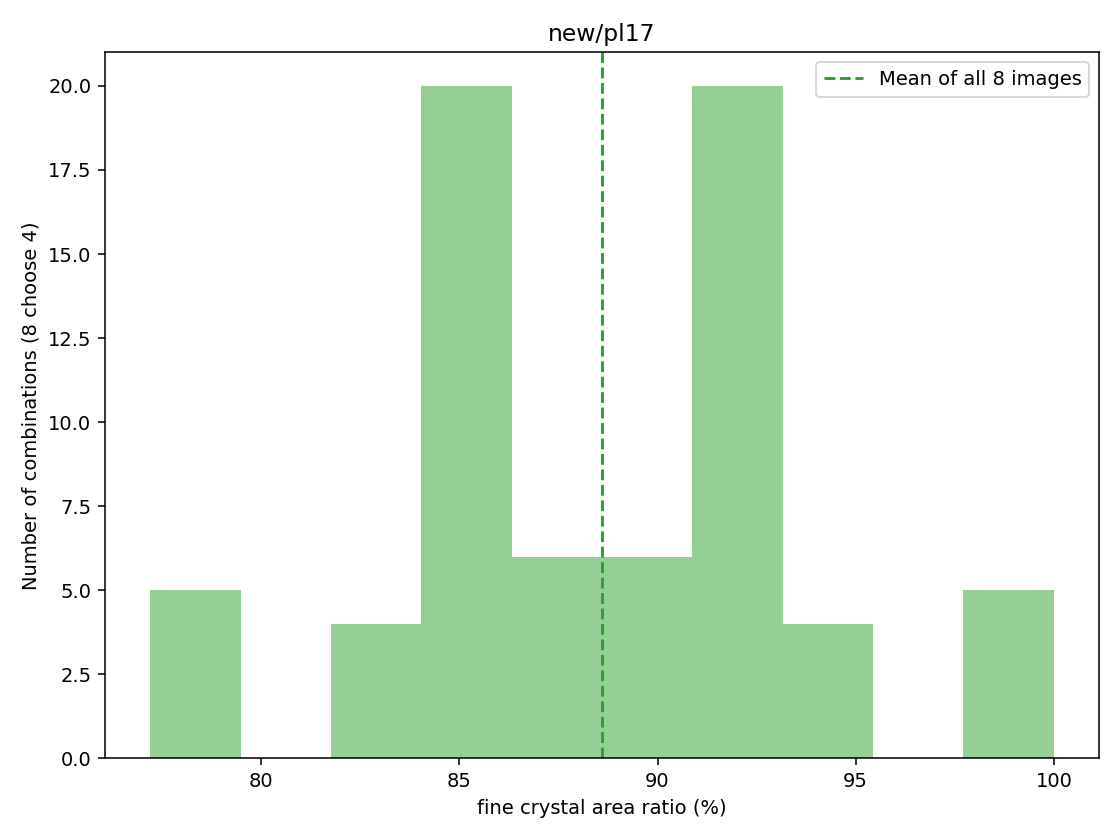

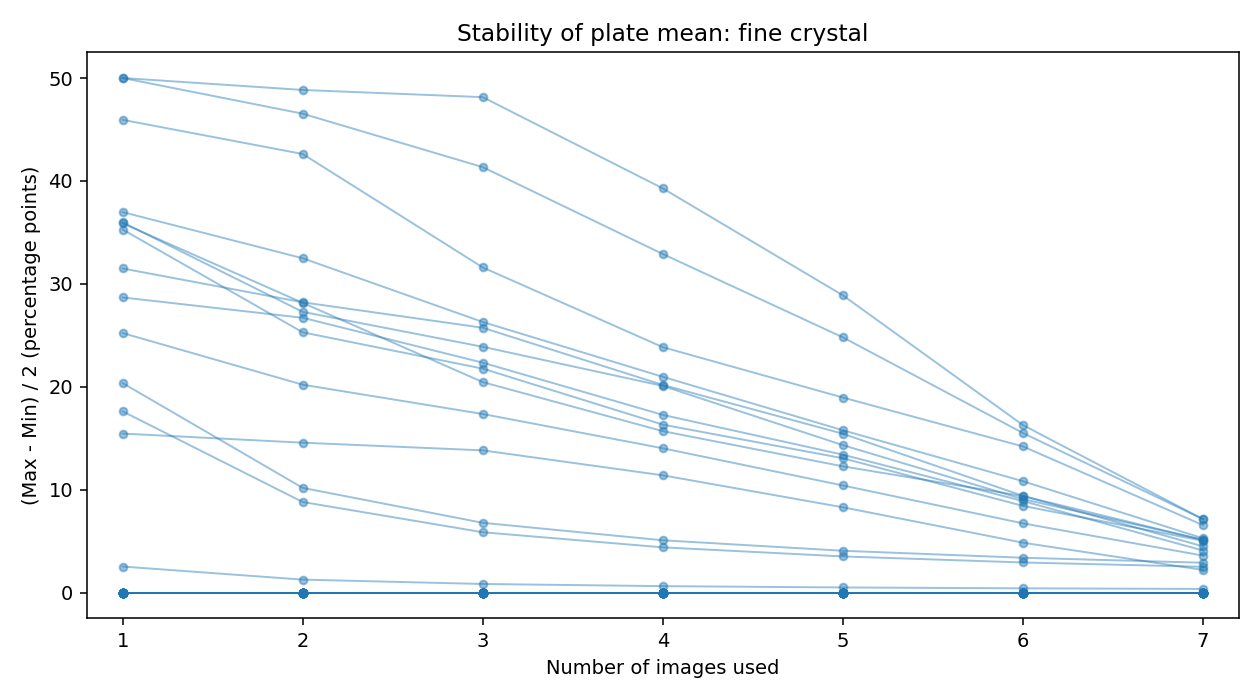

Area columns: ['class_0_area_ratio']
new/pl17: 8 images, choose 4, 70 combinations; half range: 11.401 percentage points
Output: /home/kmanabe2403/dune/implement/outputs/all_plates_step1_001/rf_corrected/sampling/fine_crystal


In [11]:
# Cell 11: Sampling systematic error — histogram and stability plot.
from crystal_sampling import analyze_sampling

AREA_CSV = RUN_DIR / "rf_corrected" / "area_ratios.csv"
# Parent label 0 includes both 0 and any 0_* subclasses present in the results.
# Archive histogram example: new/pl17, four out of eight images.
# Stability display: one color, no legend, up to seven images used.
analyze_sampling(AREA_CSV, target_labels=["0"], class_name="fine crystal", group="new", plate="pl17", n_use=4, max_error=None, max_plot_images=7)

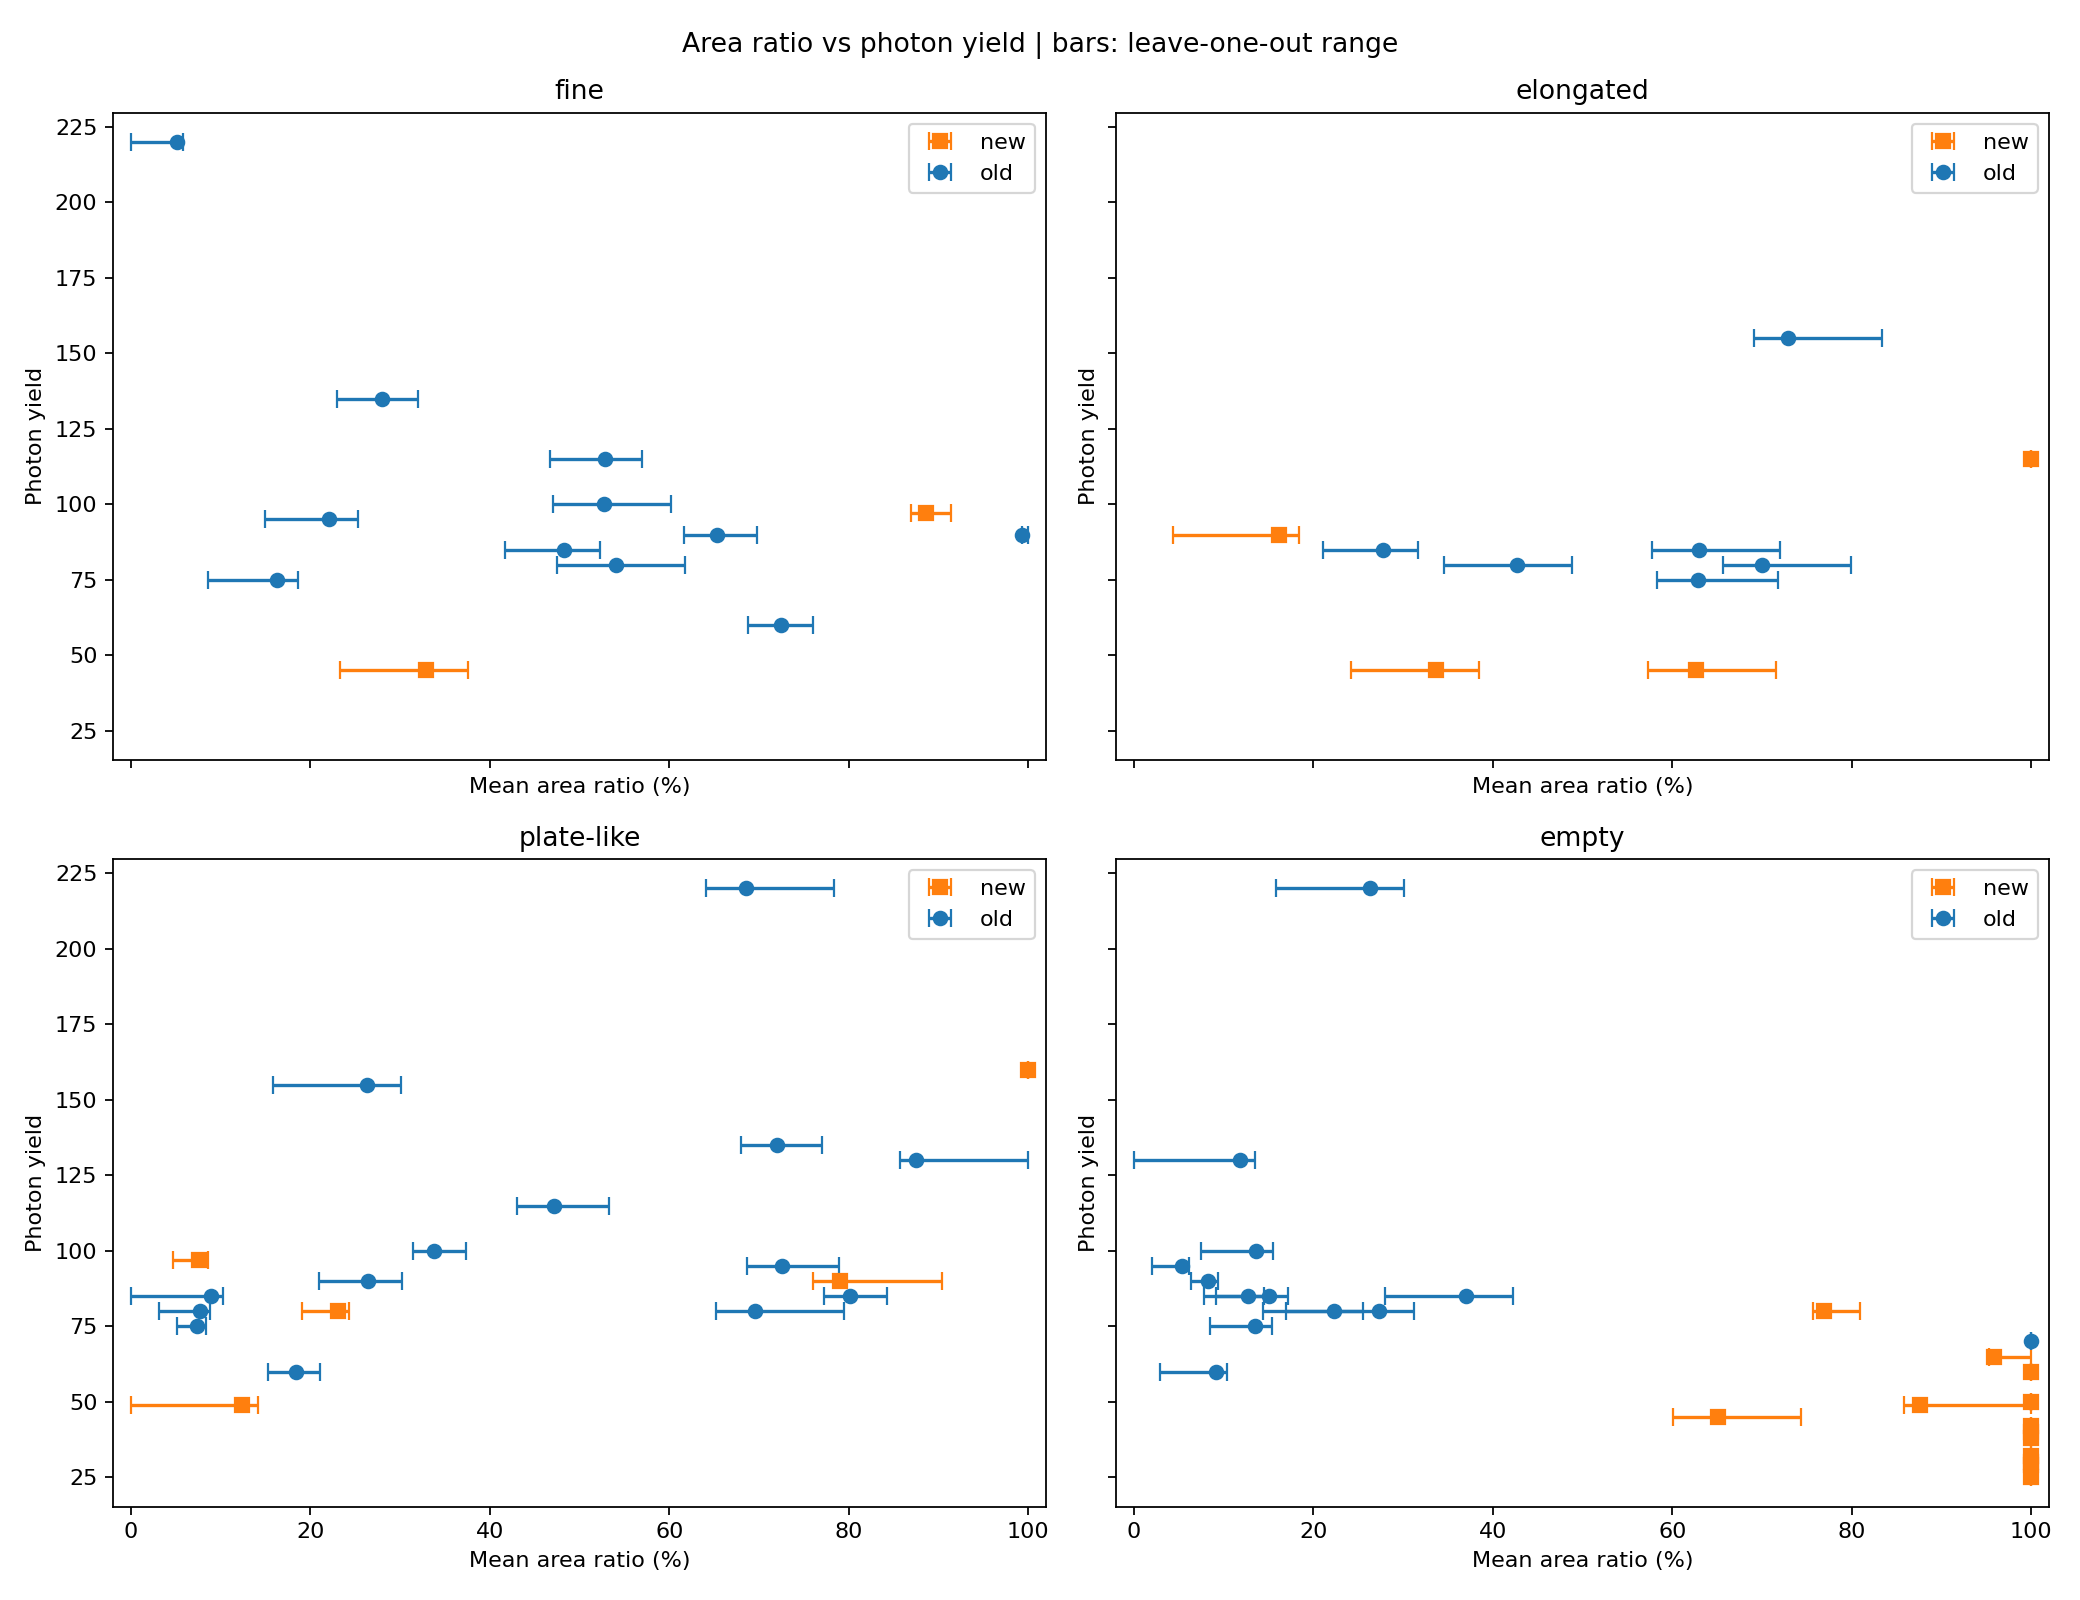

Saved 144 plate/category results: /home/kmanabe2403/dune/implement/outputs/all_plates_step1_001/rf_corrected/photon_yield


In [12]:
# Cell 12: Plot four area categories vs photon yield in a single 2-by-2 figure.
# Bars show leave-one-out ranges; means below 5% are hidden only in this figure.
from crystal_photon import plot_area_photon

CLASS_GROUPS = {
    "fine": ["0"], "elongated": ["1"],
    "plate-like": ["2"], "empty": ["3"],
}
AREA_CSV = RUN_DIR / "rf_corrected" / "area_ratios.csv"
plot_area_photon(AREA_CSV, INPUT_DIR / "tables" / "photon_yield.csv", CLASS_GROUPS, min_area=5.0)

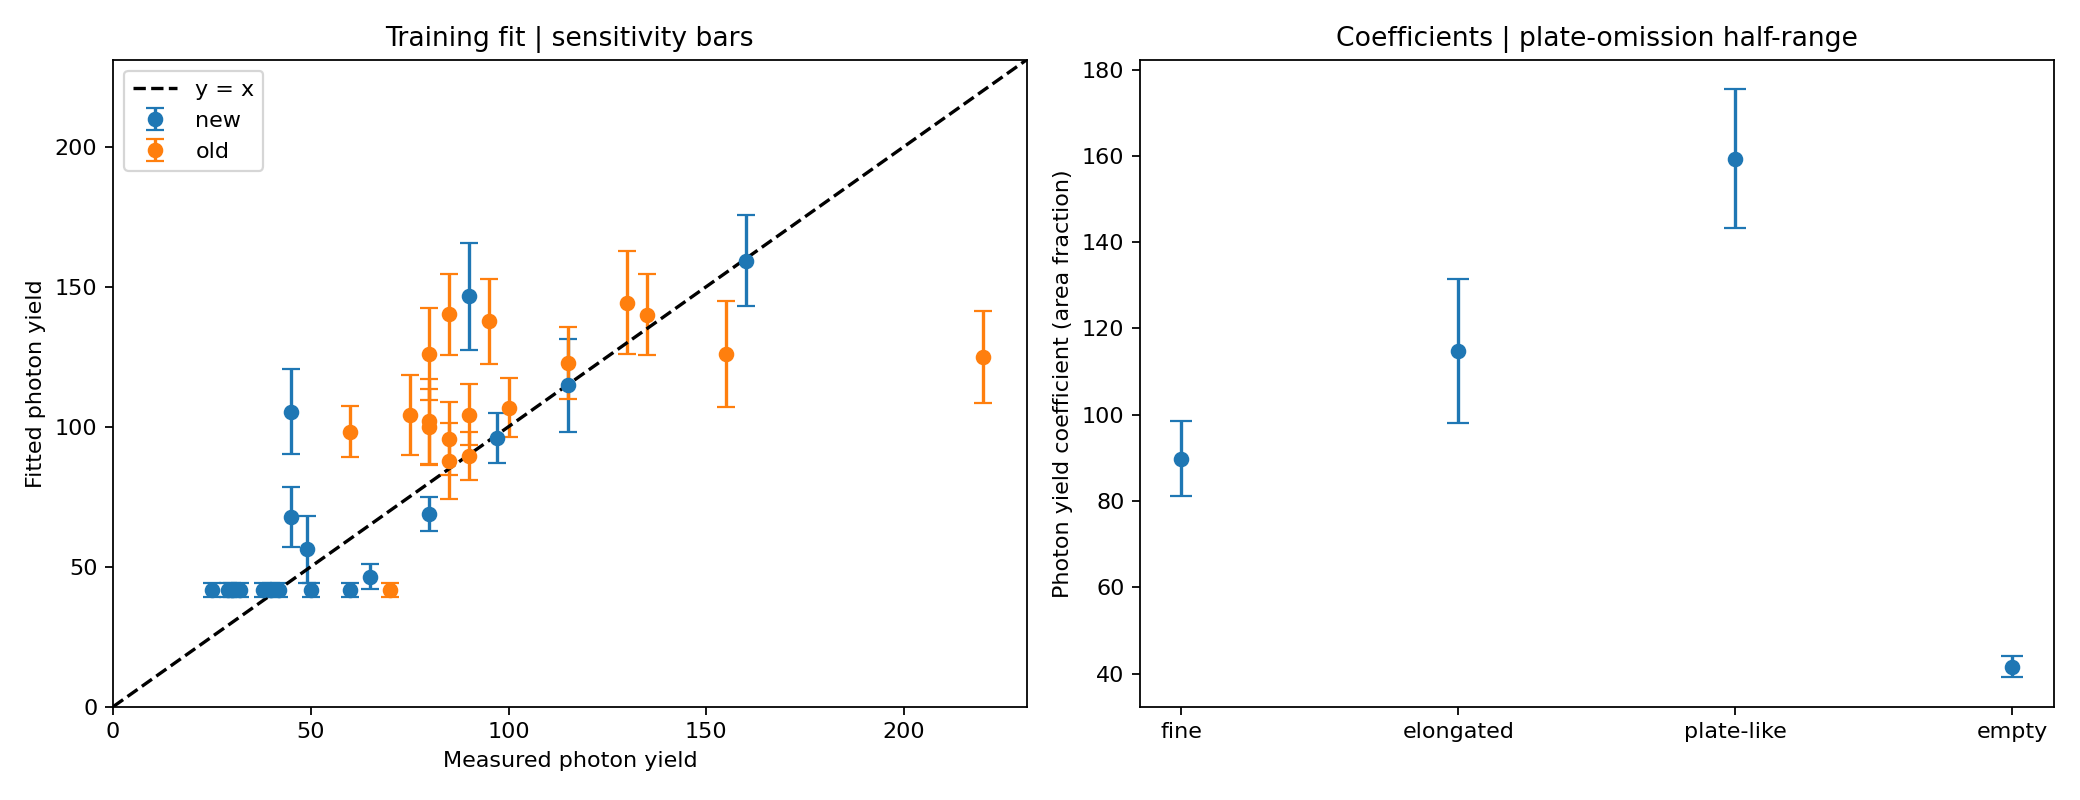

  category  coefficient  loo_half_range    loo_min    loo_max
      fine    89.850211        8.594745  72.911001  90.100490
 elongated   114.766734       16.582304  81.695539 114.860148
plate-like   159.319720       16.136511 127.451183 159.724205
     empty    41.639683        2.489685  38.501538  43.480909
Training R2: 0.5050 | Training RMSE: 29.0889 | Leave-one-plate-out RMSE: 30.4982
Output: /home/kmanabe2403/dune/implement/outputs/all_plates_step1_001/rf_corrected/photon_yield/model


In [13]:
# Cell 13: Fit the bounded weighted photon-yield model for the four area categories.
# Fit scores use training plates; plate-omission results are saved separately.
from crystal_photon_model import fit_photon_model

PLATE_CSV = AREA_CSV.parent / "photon_yield" / "plate_area_photon.csv"
fit_photon_model(PLATE_CSV, categories=list(CLASS_GROUPS), bounds=(0, 500))

## Required manual input: coverage correction

☐ Set `COVERAGE_RESULT_PATH` to GMM-area results for the coverage dataset being used.  
☐ Run Cell 14 to create `review/coverage_settings.csv`.  
☐ Inspect the corresponding coverage figures; enter `GMMlabel` and empty `cluster` IDs, then rerun.  
・Blank rows are excluded; cluster-based coverage needs two selected images per plate.  
・Current reproduction selections are retained locally; new runs receive no past selections.

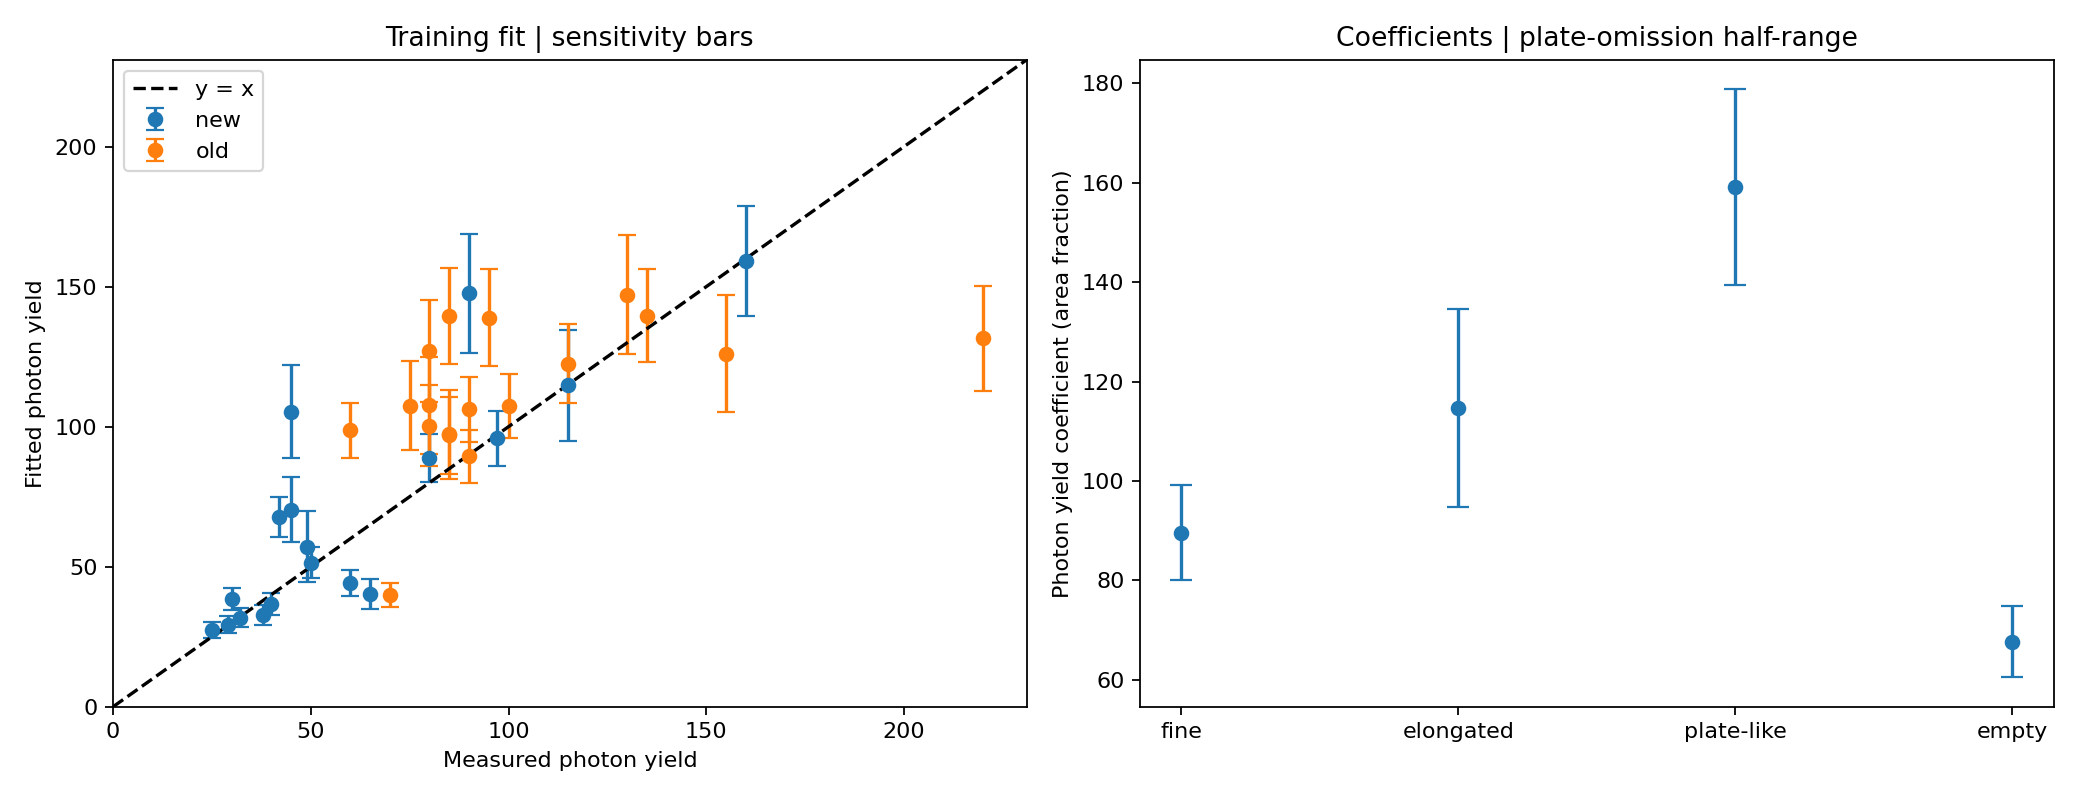

Coverage: 107 images, 18 plates; skipped settings: 131
Coverage applied to 18/36 plates; missing coverage uses factor 1.
  category  coefficient  loo_half_range    loo_min    loo_max
      fine    89.612393        9.552219  70.829352  89.933790
 elongated   114.714451       19.890885  75.027280 114.809051
plate-like   159.096864       19.737281 120.105814 159.580377
     empty    67.683994        7.164365  62.539916  76.868647
Training R2: 0.5000 | Training RMSE: 29.2346 | Leave-one-plate-out RMSE: 31.3095
Output: /home/kmanabe2403/dune/implement/outputs/all_plates_step1_001/rf_corrected/photon_yield/model_coverage


In [14]:
# Cell 14: Coverage-corrected photon model; requires run-local manual selections.
# New run: edit review/coverage_settings.csv, then rerun this cell.
# COVERAGE_RESULT_PATH must contain GMM areas for the selected plates.
from crystal_coverage import prepare_coverage_settings, fit_coverage_model

COVERAGE_RESULT_PATH = INPUT_DIR / "tables" / "coverage_result.csv"
COVERAGE_SETTINGS_PATH = prepare_coverage_settings(RUN_DIR, COVERAGE_RESULT_PATH)
fit_coverage_model(PLATE_CSV, COVERAGE_SETTINGS_PATH, COVERAGE_RESULT_PATH,
                   categories=list(CLASS_GROUPS), bounds=(0, 500))

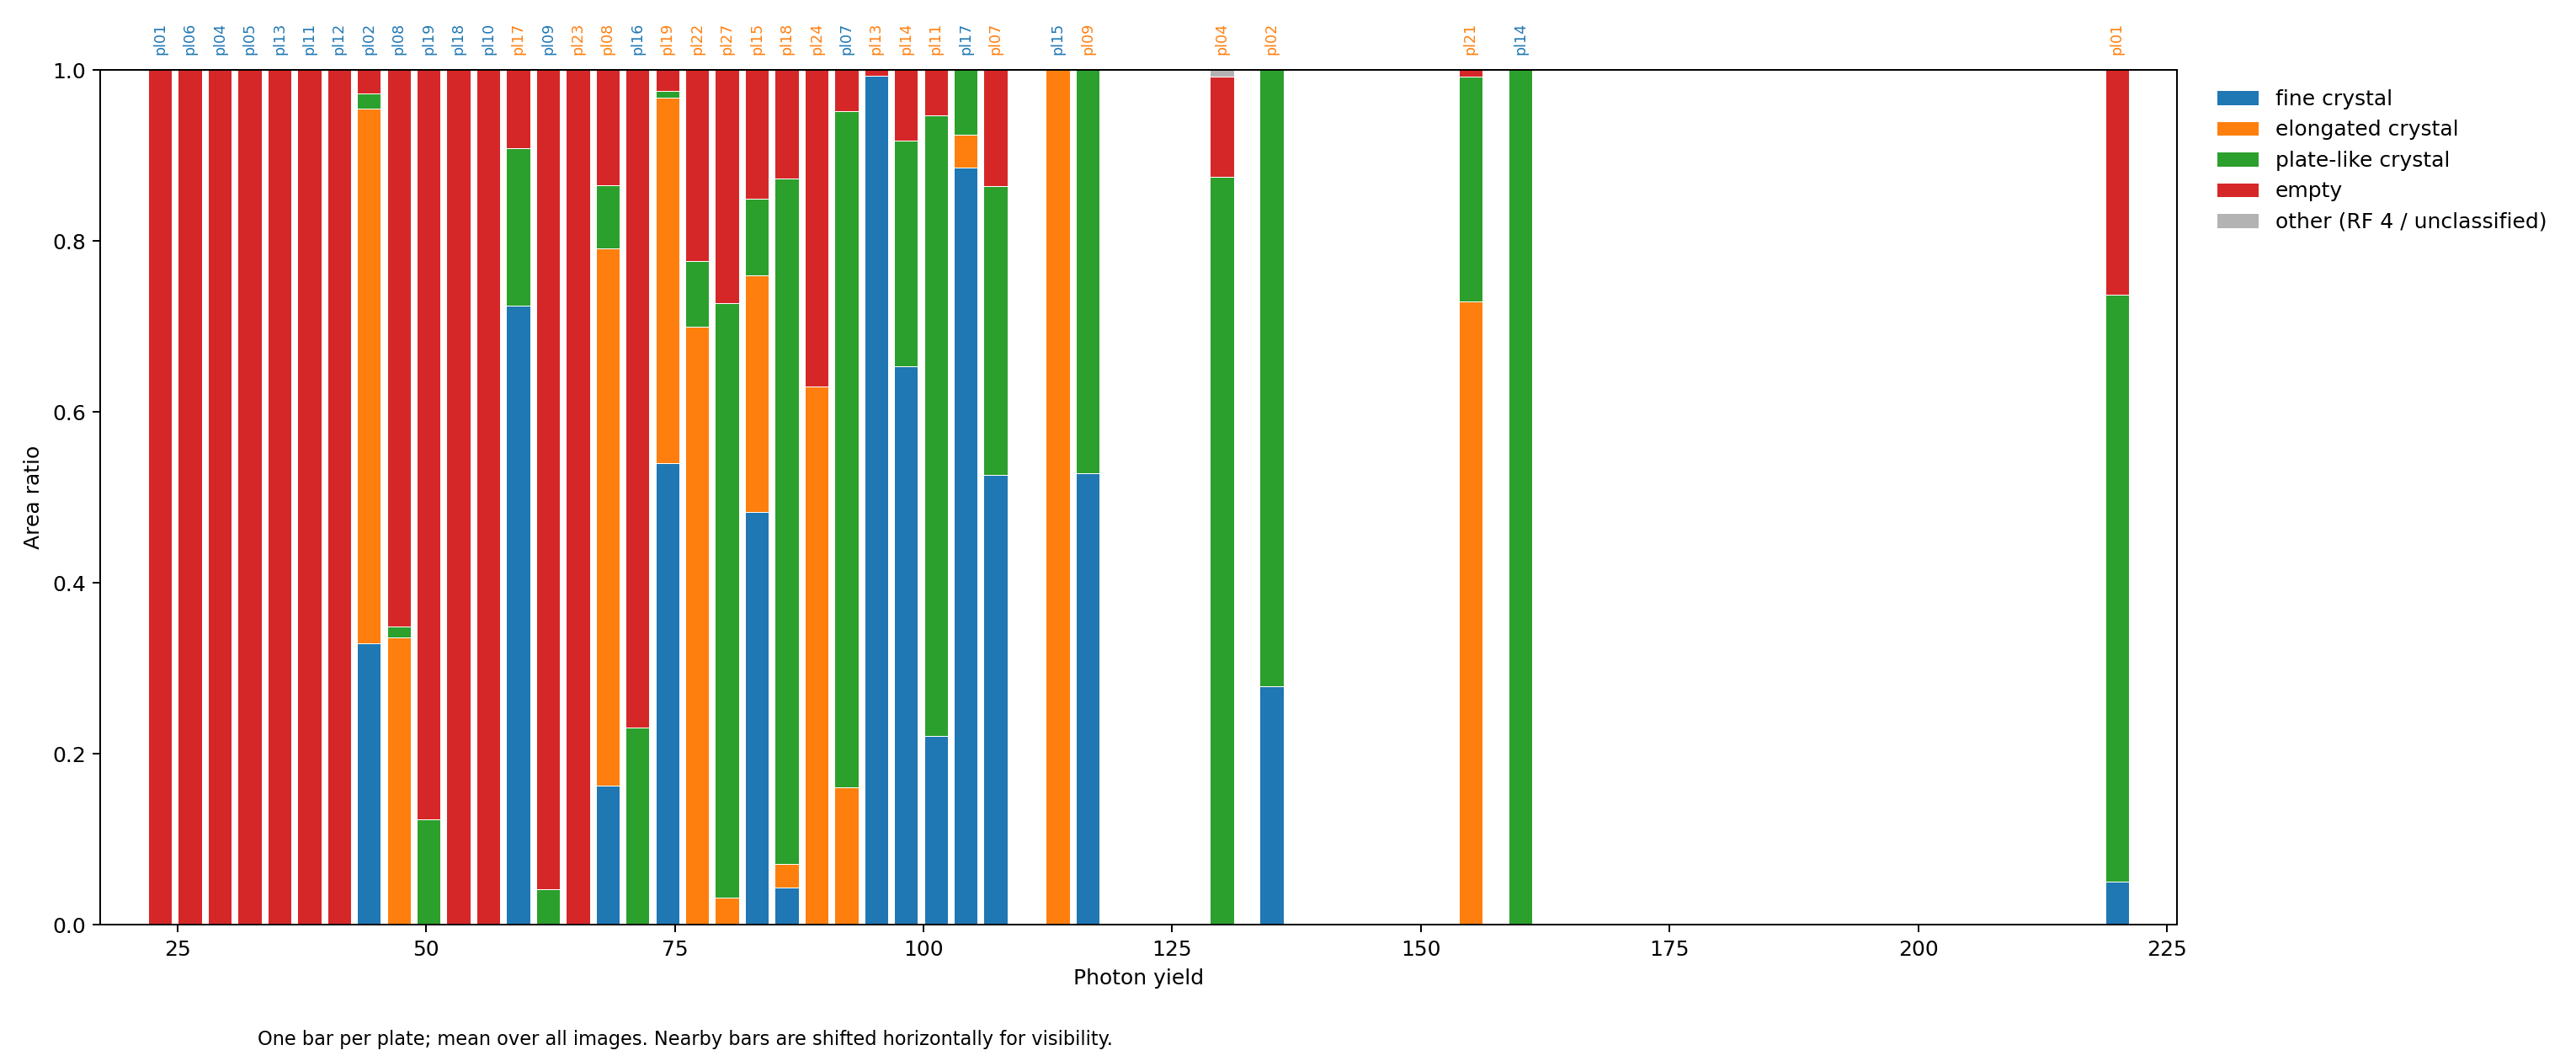

36 plates; maximum display shift: 8.76. True yields and shifts: /home/kmanabe2403/dune/implement/outputs/all_plates_step1_001/rf_corrected/photon_yield/stacked_area_photon.csv


In [15]:
# Cell 15: Plate-mean area fractions stacked against measured photon yield.
# Display positions are shifted only as needed to keep neighboring bars apart.
# Plate labels: new in blue, old in orange; the frame ends at area ratio 1.
# Fractions retain the whole-image denominator; the fifth RF class is not renormalized.
from crystal_photon import plot_stacked_area_photon

plot_stacked_area_photon(PLATE_CSV, categories=list(CLASS_GROUPS), bar_width=2.4, gap=0.6)